<a href="https://colab.research.google.com/github/Adhityayusuf/mesin-learning/blob/main/JS05/JS05_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
	import numpy as np
	from sklearn.datasets import make_classification

	# Membuat data dummy
	# Hasil dari make_classification berupa data fitur X dan label y
	# Label y akan berupa data yang sudah di encode (angka)
	X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

	# Secara defalt, make_classfication menghasilkan nilai float
	# Kita perlu merubah dalam bentuk diskrit

	# Absolutekan nilai
	X = np.absolute(X)

	# Bulatkan nilai ke 2 angka dibelakang koma
	# Kalikan dengan 100 supaya tidak ada lagi koma
	X = np.round(X, 2) * 100

	# Ubah ke dalam bentuk integer
	X = X.astype(int)

	# Cek Hasil
	print(X)
	print(y)

[[ 60   1]
 [336  77]
 [ 97 123]
 [148  16]
 [148  61]
 [ 62  55]
 [138  70]
 [115 270]
 [127  37]
 [  6 296]
 [150   9]
 [ 67 213]
 [ 42 138]
 [186  13]
 [143 121]
 [104  99]
 [250 123]
 [ 99 117]
 [ 48 176]
 [160 128]
 [149 163]
 [239 193]
 [153 107]
 [111 100]
 [152 152]
 [181 112]
 [155 210]
 [ 48  38]
 [ 78 177]
 [142  83]]
[0 0 0 0 0 0 0 0 1 1 1 0 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


In [2]:
import pandas as pd

# Reshape label y menjadi 2D
# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek Data Frame
df.head()

,Fitur 1,Fitur 2,Label
0,60,1,0
1,336,77,0
2,97,123,0
3,148,16,0
4,148,61,0


In [3]:
	# Definisikan nama label
	labels = {
	    1 : 'Kelas A',
	    0 : 'Kelas B'
	}

	# Copy Data Frame untuk menyimpan Data Frame baru
	# dengan label yang mudah untuk dibaca
	df_label = df.copy()

	# Ubah label dengan fungsi mapping dari Pandas
	# pada Data Frame df_label
	df_label['Label'] = df_label['Label'].map(labels)

	# Cek Data Frame df_label
	df_label.head()

,Fitur 1,Fitur 2,Label
0,60,1,Kelas B
1,336,77,Kelas B
2,97,123,Kelas B
3,148,16,Kelas B
4,148,61,Kelas B


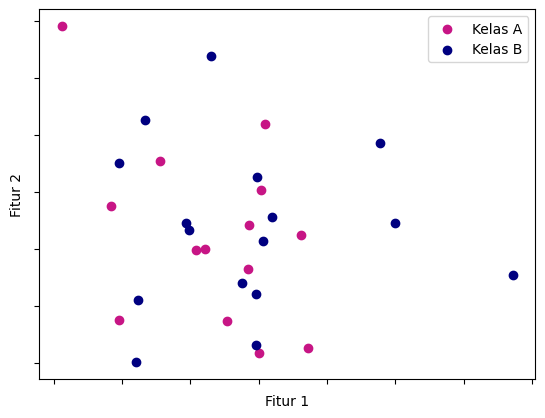

In [11]:
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
    'Kelas A': 'MediumVioletRed',
    'Kelas B': 'Navy'
}

# Perbaikan: gunakan pass nama kolom langsung tanpa list brackets atau gunakan tuple
class_a = df_label[df_label['Label'] == 'Kelas A']
class_b = df_label[df_label['Label'] == 'Kelas B']

# Plot scatter
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['Kelas A'], label='Kelas A')
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['Kelas B'], label='Kelas B')

plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend()
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

In [10]:
	from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

	# Inisiasi obyek MultinomialNB
	mnb = MultinomialNB()

	# Kita dapat langsung menggunakan fitur X dan label y
	# hasil dari proses pembuatan data dummy

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

	# Fit model
	# Label y harus dalam bentuk 1D atau (n_samples,)
	mnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred = mnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train = accuracy_score(y_train, y_train_pred)

	# Prediksi test data
	y_test_pred = mnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train: {acc_train}')
	print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.47619047619047616
Hasil akurasi data test: 0.4444444444444444
